In [2]:
import pandas as pd

# Load both CSV files
df_overview = pd.read_csv('../data/a_github_issues_overview_dataset.csv')
df_tickets = pd.read_csv('../data/github_issues_tickets.csv')

print("=== OVERVIEW DATASET ===")
print("Shape:", df_overview.shape)
print("Columns:", df_overview.columns.tolist())

print("\n=== TICKETS DATASET ===")
print("Shape:", df_tickets.shape)
print("Columns:", df_tickets.columns.tolist())

=== OVERVIEW DATASET ===
Shape: (15955, 16)
Columns: ['repo_name', 'title', 'body', 'user_login', 'created_at', 'answer_1', 'answer_2', 'answer_3', 'answer_4', 'answer_5', 'label_1', 'label_2', 'label_3', 'label_4', 'label_5', 'likes']

=== TICKETS DATASET ===
Shape: (15955, 132)
Columns: ['answers_0_author', 'answers_0_body', 'answers_0_creation_time', 'answers_1_author', 'answers_1_body', 'answers_1_creation_time', 'answers_2_author', 'answers_2_body', 'answers_2_creation_time', 'answers_3_author', 'answers_3_body', 'answers_3_creation_time', 'answers_4_author', 'answers_4_body', 'answers_4_creation_time', 'answers_5_author', 'answers_5_body', 'answers_5_creation_time', 'answers_6_author', 'answers_6_body', 'answers_6_creation_time', 'answers_7_author', 'answers_7_body', 'answers_7_creation_time', 'answers_8_author', 'answers_8_body', 'answers_8_creation_time', 'answers_9_author', 'answers_9_body', 'answers_9_creation_time', 'assignee', 'assignee_id', 'assignee_login', 'assignee_type

/var/folders/pv/k8b9vt0d595b4f8dysf433xm0000gn/T/ipykernel_38315/991665423.py:5: DtypeWarning: Columns (0: labels_0_default, 1: labels_10_color, 2: labels_10_default, 3: labels_10_name, 4: labels_10_url, 5: labels_9_description) have mixed types. Specify dtype option on import or set low_memory=False.
  df_tickets = pd.read_csv('../data/github_issues_tickets.csv')


In [3]:
# Let's look at the first row to understand the data
print("=== FIRST ISSUE TITLE ===")
print(df_tickets['title'].iloc[0])

print("\n=== FIRST ISSUE BODY ===")
print(df_tickets['body'].iloc[0])

print("\n=== FIRST ANSWER (author + content) ===")
print("Author:", df_tickets['answers_0_author'].iloc[0])
print("Body:", df_tickets['answers_0_body'].iloc[0])

print("\n=== LABEL ===")
print(df_tickets['labels_0_name'].iloc[0])

print("\n=== MILESTONE ===")
print(df_tickets['milestone_title'].iloc[0])

print("\n=== STATE ===")
print(df_tickets['state'].iloc[0])

=== FIRST ISSUE TITLE ===
Article mistake

=== FIRST ISSUE BODY ===
### Describe the problem that you experienced

I think there is a samll mistake in the tutorial in:
Step 3 - Add features to HomeComponent
Point 2.
In `app.component.ts`, in @[Component](https://angular.io/api/core/Component), update the template property with this code.

I guess it should be `home.component.ts`

It is a minor mistake, but can be misleading for newbes like me

### Enter the URL of the topic with the problem

https://angular.io/tutorial/first-app/first-app-lesson-02#step-3---add-features-to-homecomponent

### Describe what you were looking for in the documentation

_No response_

### Describe the actions that led you to experience the problem

_No response_

### Describe what you want to experience that would fix the problem

_No response_

### Add a screenshot if that helps illustrate the problem

_No response_

### If this problem caused an exception or error, please paste it here

_No response_

### 

In [4]:
# Check missing values in the columns that matter most for your thesis
important_cols = [
    'title', 'body', 'state',
    'answers_0_author', 'answers_0_body',
    'answers_1_author', 'answers_1_body',
    'answers_2_author', 'answers_2_body',
    'labels_0_name', 'labels_1_name',
    'milestone_title',
    'user_login'
]

print("=== MISSING VALUES IN KEY COLUMNS ===")
print(df_tickets[important_cols].isnull().sum())

print("\n=== TOTAL ROWS ===", len(df_tickets))

print("\n=== STATE DISTRIBUTION ===")
print(df_tickets['state'].value_counts())

=== MISSING VALUES IN KEY COLUMNS ===
title                   0
body                    0
state                   0
answers_0_author        0
answers_0_body          0
answers_1_author     3447
answers_1_body       3447
answers_2_author     6949
answers_2_body       6949
labels_0_name           9
labels_1_name        7517
milestone_title     13546
user_login              0
dtype: int64

=== TOTAL ROWS === 15955

=== STATE DISTRIBUTION ===
state
closed    15955
Name: count, dtype: int64


In [5]:
# How many answers does a typical issue have?
answer_counts = []

for i in range(10):
    col = f'answers_{i}_body'
    if col in df_tickets.columns:
        filled = df_tickets[col].notna().sum()
        answer_counts.append((f'Answer {i}', filled))

print("=== HOW MANY ISSUES HAVE EACH ANSWER ===")
for label, count in answer_counts:
    print(f"{label}: {count} issues ({round(count/len(df_tickets)*100, 1)}%)")

print("\n=== SAMPLE LABELS ===")
print(df_tickets['labels_0_name'].value_counts().head(10))

=== HOW MANY ISSUES HAVE EACH ANSWER ===
Answer 0: 15955 issues (100.0%)
Answer 1: 12508 issues (78.4%)
Answer 2: 9006 issues (56.4%)
Answer 3: 6435 issues (40.3%)
Answer 4: 4513 issues (28.3%)
Answer 5: 3114 issues (19.5%)
Answer 6: 2147 issues (13.5%)
Answer 7: 1339 issues (8.4%)
Answer 8: 755 issues (4.7%)
Answer 9: 319 issues (2.0%)

=== SAMPLE LABELS ===
labels_0_name
bug                              11632
Bug                               1223
enhancement                        525
documentation                      267
good first issue                   190
help wanted                        148
waiting for customer response      133
Documentation                       90
type/bug                            74
Issue: Ready for Work               57
Name: count, dtype: int64


In [6]:
# Taking a look at a full example of a multi-turn conversation
# to understand the structure before we clean it

row = df_tickets.iloc[1]

print("=== ISSUE TITLE ===")
print(row['title'])

print("\n=== REPORTED BY ===")
print(row['user_login'])

print("\n=== LABEL ===")
print(row['labels_0_name'])

print("\n=== CONVERSATION THREAD ===")
for i in range(10):
    author_col = f'answers_{i}_author'
    body_col = f'answers_{i}_body'
    time_col = f'answers_{i}_creation_time'
    
    if pd.notna(row.get(author_col)) and pd.notna(row.get(body_col)):
        print(f"\n--- Reply {i+1} ---")
        print(f"Author: {row[author_col]}")
        print(f"Time: {row[time_col]}")
        print(f"Message: {str(row[body_col])[:200]}")

=== ISSUE TITLE ===
Able to change the window height even if IsResizable is false but ExtendsContentIntoTitleBar is true

=== REPORTED BY ===
eduardobragaxz

=== LABEL ===
bug

=== CONVERSATION THREAD ===

--- Reply 1 ---
Author: github-actions[bot]
Time: 2024-06-07T20:52:50+00:00
Message: Hi I'm an AI powered bot that finds similar issues based off the issue title.

 Please view the issues below to see if they solve your problem, and if the issue describes your problem please consider 

--- Reply 2 ---
Author: codendone
Time: 2024-06-08T02:22:56+00:00
Message: This is very similar to #9670, though that issue is only talking about the cursor being incorrect.

I'm not able to actually resize the window **when using 1.5**, but I do repro the issue with **1.6

--- Reply 3 ---
Author: codendone
Time: 2024-07-11T02:02:16+00:00
Message: This was closed as fixed/duplicate of #7629. The fix will be in the next 1.6 release.


In [10]:
df = pd.read_csv('data/github_issues_cleaned.csv', low_memory=False)
print(df.shape)

(15955, 133)


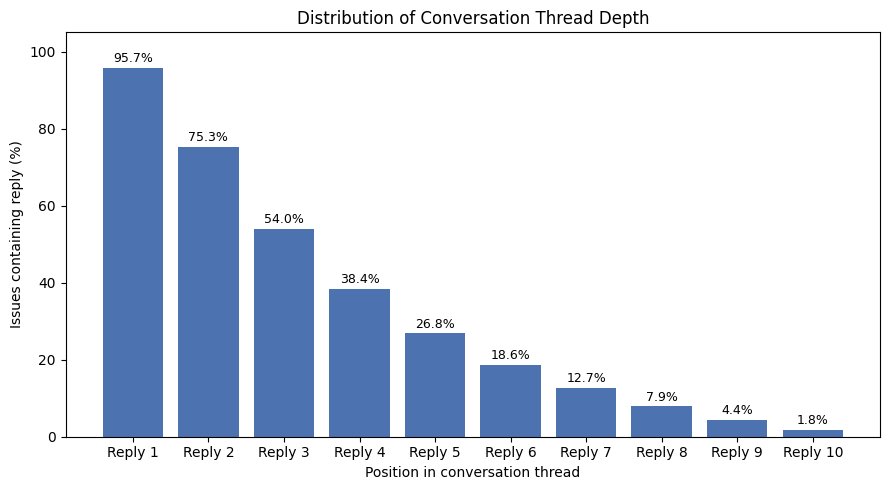

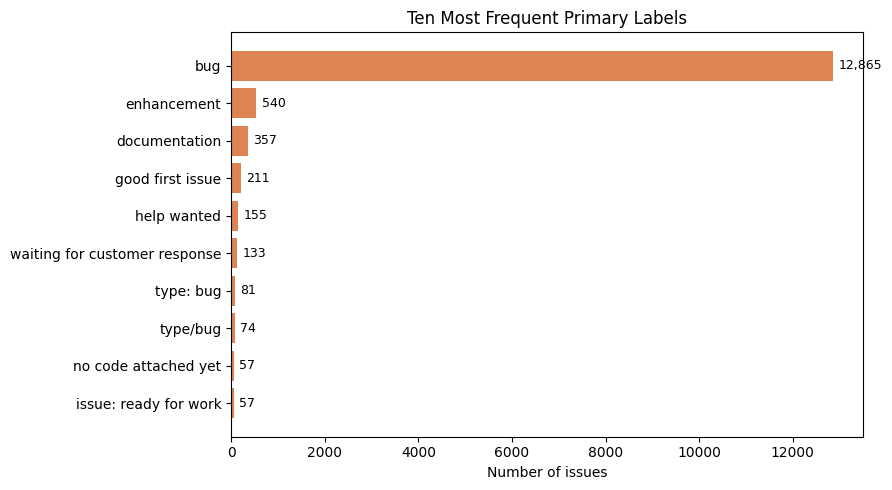

Both figures saved to results/


In [11]:
import matplotlib.pyplot as plt
import pandas as pd

# ---------- Figure 1: Answer slot population ----------
slot_counts = []
for i in range(10):
    col = f'answers_{i}_body'
    if col in df.columns:
        slot_counts.append(df[col].notna().sum())

# note: if running on github_issues_final.csv, only slots 0-5 exist
labels = [f'Reply {i+1}' for i in range(len(slot_counts))]
pct = [c / len(df) * 100 for c in slot_counts]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels, pct, color='#4C72B0')
ax.set_ylabel('Issues containing reply (%)')
ax.set_xlabel('Position in conversation thread')
ax.set_title('Distribution of Conversation Thread Depth')
ax.set_ylim(0, 105)

for bar, p in zip(bars, pct):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
            f'{p:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('results/fig_thread_depth.png', dpi=300, bbox_inches='tight')
plt.show()


# ---------- Figure 2: Top label frequency ----------
top_labels = df['labels_0_name'].value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_labels.index, top_labels.values, color='#DD8452')
ax.set_xlabel('Number of issues')
ax.set_title('Ten Most Frequent Primary Labels')

for i, v in enumerate(top_labels.values):
    ax.text(v + 120, i, f'{v:,}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('results/fig_label_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("Both figures saved to results/")

In [12]:
raw = pd.read_csv('data/github_issues_tickets.csv', low_memory=False)
print(raw['state_reason'].value_counts(dropna=False))
print(raw['comments'].dtype)

state_reason
completed      14997
not_planned      958
Name: count, dtype: int64
int64


In [13]:
import os

os.chdir('/Users/yaminiumarani/Desktop/rag_thesis_project')
raw = pd.read_csv('data/github_issues_tickets.csv', low_memory=False)

# --- Ghost accounts ---
ghost_total = 0
for i in range(10):
    c = f'answers_{i}_author'
    if c in raw.columns:
        n = (raw[c] == 'ghost').sum()
        ghost_total += n
        print(f'answers_{i}_author ghost replies: {n}')
print(f'\nTotal ghost replies: {ghost_total}')
print(f'Issues with at least one ghost reply: '
      f'{raw[[f"answers_{i}_author" for i in range(10)]].eq("ghost").any(axis=1).sum()}')

# --- Repository diversity ---
print(f'\nUnique repositories: {raw["repo_name"].nunique()}')
print(raw['repo_name'].value_counts().head(10))

answers_0_author ghost replies: 108
answers_1_author ghost replies: 85
answers_2_author ghost replies: 70
answers_3_author ghost replies: 40
answers_4_author ghost replies: 30
answers_5_author ghost replies: 22
answers_6_author ghost replies: 18
answers_7_author ghost replies: 13
answers_8_author ghost replies: 5
answers_9_author ghost replies: 5

Total ghost replies: 396
Issues with at least one ghost reply: 275

Unique repositories: 986
repo_name
godotengine/godot                              206
material-components/material-components-web    163
flutter/flutter                                152
sveltejs/svelte                                149
elastic/kibana                                 140
boto/boto3                                     138
ocornut/imgui                                  132
magento/magento2                               115
scikit-learn/scikit-learn                      115
Gravitational/teleport                         112
Name: count, dtype: int64


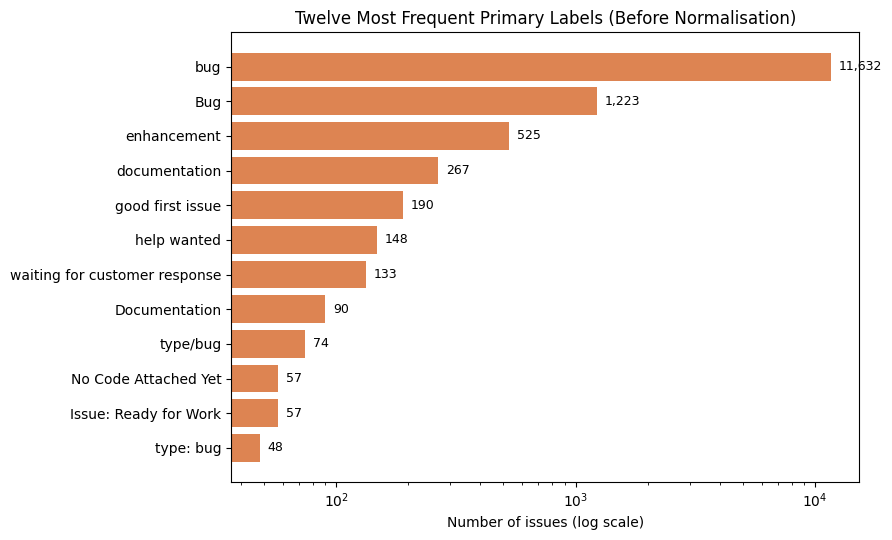

In [14]:
# --- Figure 2: label distribution (raw, shows case inconsistency) ---
top = raw['labels_0_name'].value_counts().head(12).sort_values()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index, top.values, color='#DD8452')
ax.set_xlabel('Number of issues (log scale)')
ax.set_xscale('log')
ax.set_title('Twelve Most Frequent Primary Labels (Before Normalisation)')
for i, v in enumerate(top.values):
    ax.text(v * 1.08, i, f'{v:,}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('results/fig_label_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

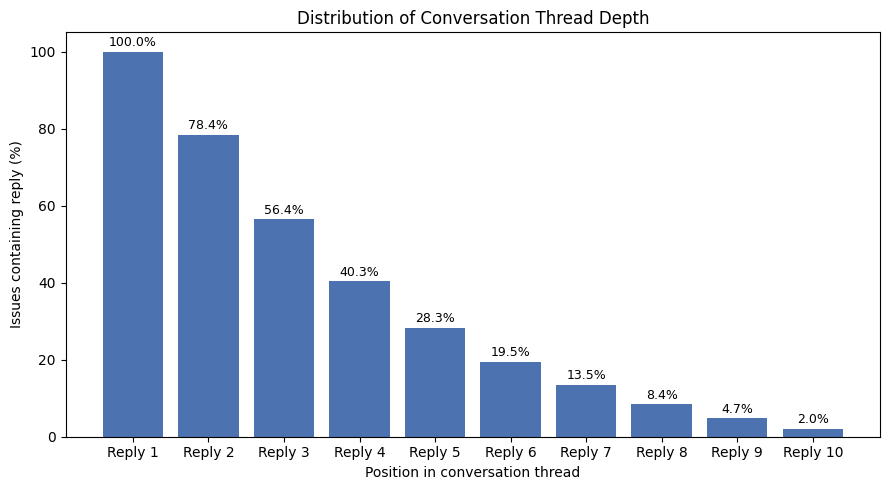

In [15]:
# --- Figure 1: thread depth (raw) ---
slot_counts = [raw[f'answers_{i}_body'].notna().sum() for i in range(10)]
pct = [c / len(raw) * 100 for c in slot_counts]
labels = [f'Reply {i+1}' for i in range(10)]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels, pct, color='#4C72B0')
ax.set_ylabel('Issues containing reply (%)')
ax.set_xlabel('Position in conversation thread')
ax.set_title('Distribution of Conversation Thread Depth')
ax.set_ylim(0, 105)
for bar, p in zip(bars, pct):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
            f'{p:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('results/fig_thread_depth.png', dpi=300, bbox_inches='tight')
plt.show()